In [1]:
from pathlib import Path  # clean file paths

import geopandas as gpd  # maps and the grid
import matplotlib.pyplot as plt  # charts
import numpy as np  # math helpers
import pandas as pd  # tables

ROOT = Path("..")  # the notebook runs inside notebooks/, so the project root is one level up
DATA = ROOT / "data" / "processed"  # where all cleaned tables live
FIG_DIR = ROOT / "reports" / "figures"  # where charts get saved for the README
FIG_DIR.mkdir(parents=True, exist_ok=True)  # create the folder if it doesn't exist

plt.style.use("seaborn-v0_8-whitegrid")  # clean style with a light grid
plt.rcParams["figure.figsize"] = (10, 4)  # default chart size: wide and short
plt.rcParams["figure.dpi"] = 110  # slightly sharper charts in the notebook
pd.set_option("display.max_columns", 30)  # show all columns instead of "..."


def save_fig(name):  # save the current chart under reports/figures
    plt.tight_layout()  # stop labels from being cut off
    plt.savefig(FIG_DIR / f"{name}.png", dpi=150, bbox_inches="tight")  # high-quality PNG for the README
    print("Saved", name)  # confirm

In [2]:
fires = pd.read_parquet(DATA / "fires_with_cells.parquet")  # fire detections with cell_id
grid = gpd.read_file(DATA / "lebanon_grid.gpkg")  # 488 cells with their shapes, for maps
terrain = pd.read_parquet(DATA / "terrain.parquet")  # per-cell terrain stats
ndvi = pd.read_parquet(DATA / "ndvi.parquet")  # NDVI per cell per 8-day composite
weather = pd.read_parquet(DATA / "weather_daily.parquet")  # daily weather per cell (2012–2015 for now)

for name, df in [("fires", fires), ("grid", grid), ("terrain", terrain), ("ndvi", ndvi), ("weather", weather)]:  # loop over every table
    print(f"{name:8s} {df.shape}")  # name padded to 8 characters, then (rows, cols)

print(fires["hotspot"].value_counts())  # check what this Day 3 flag contains before we use the fires

fires    (9527, 11)
grid     (488, 5)
terrain  (488, 9)
ndvi     (323544, 6)
weather  (672786, 9)
hotspot
False    8568
True      959
Name: count, dtype: int64


## 1. Are flagged hotspots really non-wildfire heat sources?

Saved 01_hotspot_monthly_profile


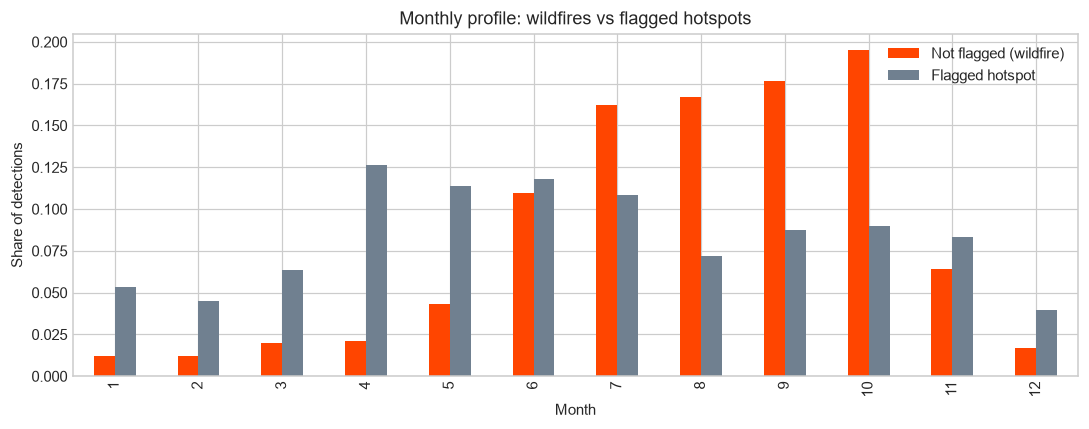

     lat    lon  detections  years  cell_id
0  34.45  35.85         136     15      242
1  33.50  35.34          93     14       37
2  34.31  35.72          92     14      164
3  33.63  35.42          71     13       53
4  33.75  35.50          69      7       72
5  34.46  35.89          53     11      242
6  34.49  36.30          49     11      413
7  34.47  35.89          44     10      242


In [3]:
fires["month"] = fires["acq_date"].dt.month  # calendar month of each detection (1-12)
monthly = fires.groupby(["month", "hotspot"]).size().unstack(fill_value=0)  # count per month, one column for flagged and one for not flagged
monthly_share = monthly / monthly.sum()  # turn counts into the share of each group's detections per month, so both fit one chart

monthly_share.plot(kind="bar", color={False: "orangered", True: "slategray"})  # side-by-side bars: wildfires orange, hotspots gray
plt.title("Monthly profile: wildfires vs flagged hotspots")  # chart title
plt.xlabel("Month")  # x-axis label
plt.ylabel("Share of detections")  # y-axis label
plt.legend(["Not flagged (wildfire)", "Flagged hotspot"])  # readable legend labels
save_fig("01_hotspot_monthly_profile")  # save for the README
plt.show()  # display the chart

spots = (  # summarize each flagged ~1 km spot
    fires[fires["hotspot"]]  # only flagged detections
    .assign(lat=lambda d: d["latitude"].round(2), lon=lambda d: d["longitude"].round(2))  # same ~1 km rounding as Day 3
    .groupby(["lat", "lon"])  # one group per spot
    .agg(detections=("acq_date", "size"), years=("acq_date", lambda s: s.dt.year.nunique()), cell_id=("cell_id", "first"))  # size, number of active years, and the cell it sits in
    .sort_values("detections", ascending=False)  # biggest first
    .reset_index()  # lat and lon back to normal columns
)  # end of summary
print(spots.head(8))  # the 8 busiest flagged spots

**Finding:** Flagged hotspots burn all year (flat monthly profile), while real wildfires peak Jul–Oct.
The busiest flagged spots sit on power plants and cement factories (Deir Ammar, Zahrani, Chekka, Jiyeh).
→ Day 7: exclude `hotspot == True` detections from the fire target.

## 2. Target: fire in the cell tomorrow

In [4]:
real = fires[~fires["hotspot"]]  # keep only real wildfires (drop the industrial hotspots)
fire_days = real[["cell_id", "acq_date"]].drop_duplicates().rename(columns={"acq_date": "date"})  # one row per cell per day with at least one fire
fire_days["fire"] = 1  # mark those cell-days as burning

dates = pd.date_range(fires["acq_date"].min(), fires["acq_date"].max(), freq="D")  # every day from the first to the last detection
panel = pd.MultiIndex.from_product([grid["cell_id"], dates], names=["cell_id", "date"]).to_frame(index=False)  # every cell × every day, as a table

panel = panel.merge(fire_days, on=["cell_id", "date"], how="left")  # attach the fire mark where it exists
panel["fire"] = panel["fire"].fillna(0).astype("int8")  # no fire = 0; int8 uses 8x less memory than the default
panel = panel.sort_values(["cell_id", "date"]).reset_index(drop=True)  # order by cell, then by day, so "tomorrow" is the next row
panel["fire_tomorrow"] = panel.groupby("cell_id")["fire"].shift(-1)  # pull the next day's value up, within each cell only
panel = panel.dropna(subset=["fire_tomorrow"])  # the last day of each cell has no tomorrow, so drop it
panel["fire_tomorrow"] = panel["fire_tomorrow"].astype("int8")  # back to small whole numbers

n_pos = int(panel["fire_tomorrow"].sum())  # number of positive rows (fire tomorrow)
rate = panel["fire_tomorrow"].mean()  # share of positive rows
print(f"Rows: {len(panel):,}")  # total cell-days
print(f"Positives: {n_pos:,} ({rate:.3%})")  # how many fire-tomorrow rows, and their percent
print(f"Negatives per positive: {(1 - rate) / rate:,.0f}")  # imbalance ratio: how many no-fire rows for each fire row

season = panel["date"].dt.month.between(7, 10)  # True for July to October
print(f"Positive rate in fire season (Jul-Oct): {panel.loc[season, 'fire_tomorrow'].mean():.3%}")  # rate during the season
print(f"Positive rate outside the season: {panel.loc[~season, 'fire_tomorrow'].mean():.3%}")  # rate for the rest of the year

Rows: 2,630,808
Positives: 5,313 (0.202%)
Negatives per positive: 494
Positive rate in fire season (Jul-Oct): 0.390%
Positive rate outside the season: 0.104%


**Finding:** 2.63M cell-days, only 0.20% positive (1 fire per ~494 non-fire days).
Fire season (Jul–Oct) is ~4× riskier than the rest of the year, but still 99.6% negative.
→ Day 8+: no accuracy; use PR-AUC and recall in the top-ranked cells. Handle imbalance with class weights, never by resampling before the split.

## 3. When do fires happen?

C:\Users\shadows box\AppData\Local\Temp\ipykernel_23664\1847504008.py:13: Pandas4Warning: Series.dt.dayofweek is deprecated and will be removed in a future version. Use Series.dt.day_of_week instead.
  dow = panel.groupby(panel["date"].dt.dayofweek)["fire"].mean() * 100  # percent of cell-days burning, per weekday (0 = Monday)


Saved 02_fire_timing


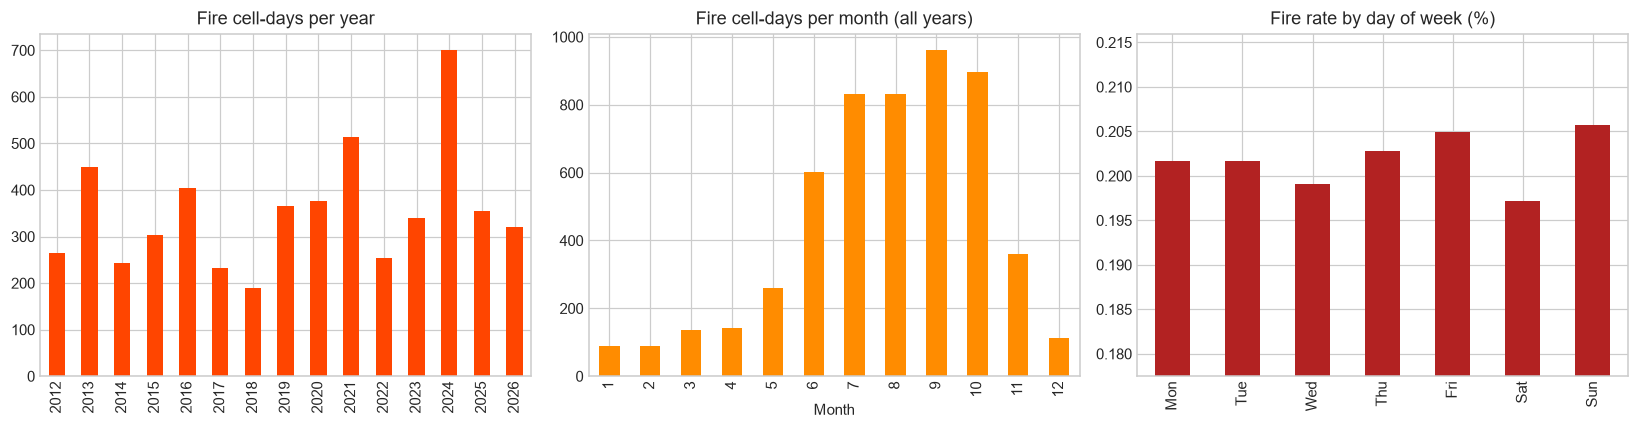

date
2024    701
2021    513
2013    449
2016    405
Name: fire, dtype: int64
Busiest weekday / quietest weekday: 1.04x


In [ ]:
fig, axes = plt.subplots(1, 3, figsize=(15, 4))  # three charts side by side

yearly = panel.groupby(panel["date"].dt.year)["fire"].sum()  # fire cell-days per year
yearly.plot(kind="bar", ax=axes[0], color="orangered")  # bar per year
axes[0].set_title("Fire cell-days per year")  # title
axes[0].set_xlabel("")  # the years explain themselves

monthly = panel.groupby(panel["date"].dt.month)["fire"].sum()  # fire cell-days per calendar month, all years together
monthly.plot(kind="bar", ax=axes[1], color="darkorange")  # bar per month
axes[1].set_title("Fire cell-days per month (all years)")  # title
axes[1].set_xlabel("Month")  # x-axis label

dow = panel.groupby(panel["date"].dt.day_of_week)["fire"].mean() * 100  # percent of cell-days burning, per weekday (0 = Monday); day_of_week is the new name
dow.index = ["Mon", "Tue", "Wed", "Thu", "Fri", "Sat", "Sun"]  # readable weekday names
dow.plot(kind="bar", ax=axes[2], color="firebrick")  # bar per weekday
axes[2].set_title("Fire rate by day of week (%)")  # title
axes[2].set_ylim(dow.min() * 0.9, dow.max() * 1.05)  # zoom the y-axis so small differences are visible
axes[2].set_xlabel("")  # weekday names explain themselves

save_fig("02_fire_timing")  # save for the README
plt.show()  # display the three charts

print(yearly.sort_values(ascending=False).head(4))  # the 4 worst years
print(f"Busiest weekday / quietest weekday: {dow.max() / dow.min():.2f}x")  # how strong the weekday effect is